In [46]:
import sys
from pathlib import Path
 
print(sys.executable)
print(Path.cwd())

C:\Users\chukk\desktop\ironhack\week_6\day_1\vanguard-FCCP-Solutions\.venv\Scripts\python.exe
C:\Users\chukk\desktop\ironhack\week_6\day_1\vanguard-FCCP-Solutions\notebooks


In [47]:
from pathlib import Path
 
print(Path.cwd())

C:\Users\chukk\desktop\ironhack\week_6\day_1\vanguard-FCCP-Solutions\notebooks


In [48]:
import pandas as pd

In [50]:
df = pd.read_csv("../data/raw/df_final_web_data_pt_2.csv")
 
df.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,763412,601952081_10457207388,397475557_40440946728_419634,confirm,2017-06-06 08:56:00
1,6019349,442094451_91531546617,154620534_35331068705_522317,confirm,2017-06-01 11:59:27
2,6019349,442094451_91531546617,154620534_35331068705_522317,step_3,2017-06-01 11:58:48
3,6019349,442094451_91531546617,154620534_35331068705_522317,step_2,2017-06-01 11:58:08
4,6019349,442094451_91531546617,154620534_35331068705_522317,step_1,2017-06-01 11:57:58


In [152]:
df['date_time'] = pd.to_datetime(df['date_time'])

In [153]:
print('-'*10 + 'The shape of the dataframe is ' + '-'*10)
print(df.shape)
print('\n' +'-'*10 + 'The unique values per column are ' + '-'*10)
display(df.nunique(dropna = True))
print('\n' +'-'*10 + 'The data types are ' + '-'*10)
df.dtypes

----------The shape of the dataframe is ----------
(412264, 5)

----------The unique values per column are ----------


client_id        67430
visitor_id       71042
visit_id         82841
process_step         5
date_time       346697
dtype: int64


----------The data types are ----------


client_id                int64
visitor_id                 str
visit_id                   str
process_step               str
date_time       datetime64[us]
dtype: object

In [151]:
df.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,763412,601952081_10457207388,397475557_40440946728_419634,confirm,2017-06-06 08:56:00
1,6019349,442094451_91531546617,154620534_35331068705_522317,confirm,2017-06-01 11:59:27
2,6019349,442094451_91531546617,154620534_35331068705_522317,step_3,2017-06-01 11:58:48
3,6019349,442094451_91531546617,154620534_35331068705_522317,step_2,2017-06-01 11:58:08
4,6019349,442094451_91531546617,154620534_35331068705_522317,step_1,2017-06-01 11:57:58


In [52]:
print('-'*10 + 'The missing data per column is ' + '-'*10)
print(df.isna().sum())
print('\n' +'-'*10 + 'The rows missing data are ' + '-'*10)
missing_rows = df[df.isna().any(axis=1)]
print(missing_rows)

----------The missing data per column is ----------
client_id       0
visitor_id      0
visit_id        0
process_step    0
date_time       0
dtype: int64

----------The rows missing data are ----------
Empty DataFrame
Columns: [client_id, visitor_id, visit_id, process_step, date_time]
Index: []


In [53]:
print('-'*10 + 'The value counts the 5  process steps are ' + '-'*10)
steps = df['process_step'].value_counts()
display(steps)

----------The value counts the 5  process steps are ----------


process_step
start      135035
step_1      89761
step_2      71294
step_3      58614
confirm     57560
Name: count, dtype: int64

<Axes: xlabel='process_step'>

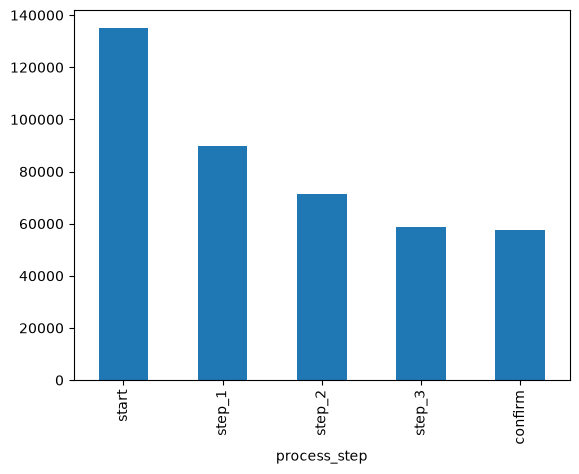

In [54]:
print('-'*10 + 'Distribution of the 5 process steps' + '-'*10)
steps.plot.bar()

In [136]:
print('-'*10 + 'Summary statistics of client_id, sessions, and visits' + '-'*10)
df_unique = df.groupby('client_id').agg(
    client_device_combo = ('visitor_id', 'nunique'),
    unique_visits = ('visit_id', 'nunique')
).reset_index()

----------Summary statistics of client_id, sessions, and visits----------


In [137]:
df_unique.describe().map(lambda x: f'{x:,.2f}')

,client_id,client_device_combo,unique_visits
count,"67,430.00","67,430.00","67,430.00"
mean,"5,020,668.53",1.07,1.24
std,"2,884,307.28",0.29,0.59
min,336.00,1.00,1.00
25%,"2,530,164.00",1.00,1.00
50%,"5,026,451.00",1.00,1.00
75%,"7,519,464.75",1.00,1.00
max,"9,999,875.00",13.00,17.00


In [119]:
print('-'*10 + 'Max combination of client_id and visitor_id combintions' + '-'*10)
print(df.groupby('client_id')['visitor_id'].nunique().max())

----------Max combination of client_id and visitor_id combintions----------
13


In [120]:
print('-'*10 + 'Max combination of visitor_id and client_id combinations' + '-'*10)
print(df.groupby('visitor_id')['client_id'].nunique().max())

----------Max combination of visitor_id and client_id combinations----------
4


In [121]:
print('-'*10 + 'Max combination of visitor_id and visit_id' + '-'*10)
print(df.groupby('visitor_id')['visit_id'].nunique().max())

----------Max combination of visitor_id and visit_id----------
13


In [122]:
print('-'*10 + 'Max combination of visit_id and visitor_id' + '-'*10)
print(df.groupby('visit_id')['visitor_id'].nunique().max())

----------Max combination of visit_id and visitor_id----------
1


In [123]:
print('-'*10 + 'Max combination of client_id and visit_id combintions' + '-'*10)
print(df.groupby('client_id')['visit_id'].nunique().max())

----------Max combination of client_id and visit_id combintions----------
17


In [124]:
print('-'*10 + 'Max combination of client_id and visit_id combintions' + '-'*10)
print(df.groupby('visit_id')['client_id'].nunique().max())

----------Max combination of client_id and visit_id combintions----------
3


Client $\rightarrow$ Visitor = 13 (1 client can use up to 13 devices/browser cookies)   
Visitor $\rightarrow$ Client = 4 (1 device/browser cookie can be used by up to 4 clients)

Visitor $\rightarrow$ Visit = 13 (1 device/browser cookie can generate up to 13 web sessions)  
Visit $\rightarrow$ Visitor = 1 (1 web session is strictly tied to 1 device/browser cookie)   

Client $\rightarrow$ Visit = 17 (1 client can have up to 17 web sessions across all their devices)   
Visit $\rightarrow$ Client = 3 (1 web session can involve up to 3 clients logging in sequentially on that device)  

Examples:

Your dad can use 13 different devices to log into the Vanguard website.

3 people and your dad can use the family computer to log in.   

The computer at the bank can be used for 13 separate browsing sessions on the Vanguard website.

Each browsing session is strictly tied to 1 computer or device.   

Your dad can have up to 17 unique visits to the web portal sessions within the data period.

Up to 3 people can log in and out back-to-back within the exact same browsing session (visit_id).

In [148]:
print('-'*10 + 'The number of clients with 2 or more client-device combos' + '-'*10)
df_two_plus_device_combos = df_unique[df_unique['client_device_combo'] >= 2]
df_two_plus_device_combos.nunique()

----------The number of clients with 2 or more client-device combos----------


client_id              3888
client_device_combo       9
unique_visits            11
dtype: int64

In [147]:
print('-'*10 + 'The number of clients with 2 or more unique visits' + '-'*10)
df_two_plus_unique_visits = df_unique[df_unique['unique_visits'] >= 2]
df_two_plus_unique_visits.nunique()

----------The number of clients with 2 or more unique visits----------


client_id              12521
client_device_combo       10
unique_visits             12
dtype: int64

In [155]:
df.to_csv("../data/clean/df_final_web_data_pt_2.csv", index=False)